# 数据结构与科学计算 · 第 08 讲
## NumPy/JAX 数据布局、向量化与可微分数值求解

> **课程定位**：面向已经学习 Python 基础、正在准备自行编写二维 CFD 求解器的学习者。本讲从数据结构原理出发，以实际数值计算问题作为应用练习。

**完成本讲后，你应该能够：**

1. 理解数组形状、内存布局和向量化对计算性能的影响；
2. 区分 JAX 的函数式更新与 NumPy 的原地修改；
3. 正确使用 `jax.jit`、`jax.vmap`、`jax.grad` 和 `lax.scan`；
4. 编写二维周期边界扩散方程离散算子与稳定时间推进；
5. 对一个模拟器参数求梯度，体验“可微分 PDE 求解器”的基本思想。

**预计学习时间**：110–160 分钟。所有核心示例可在 VS Code 的 Jupyter Notebook 中直接运行。

## 0. 使用方法与运行环境

1. 在 VS Code 打开此 `.ipynb`，右上角选择当前项目的 Python Kernel；
2. 使用 `Shift + Enter` 依次运行。修改代码后，建议 **Restart Kernel & Run All** 以消除旧变量干扰；
3. **练习单元以 `TODO` 留空**，后面会有逐项自动检查；未完成练习时显示“尚未通过”是预期行为；
4. 最后附有独立命名的 `_solution` 参考实现，不会覆盖你的练习函数；
5. 学习重点是“选择什么结构、为什么、代价是什么”，不只是背诵 API。

前两讲已安装 NumPy。本系列推荐运行 `uv pip install numpy scipy matplotlib ipykernel jupyter`。第 08 讲还需要 JAX：`uv pip install -U jax`（此命令默认安装适用于当前平台的发行版，GPU 支持视平台而定）。

In [1]:
import sys
print('Python:', sys.version.split()[0])
print('Notebook 已连接到 Python Kernel')

Python: 3.13.5
Notebook 已连接到 Python Kernel


## 1. 先明确：JAX 是什么，不是什么？

JAX 是面向数组编程、自动微分、编译转换和加速器计算的 Python 数值计算库。它不是一套自动保证数值方法正确、自动生成高质量 CFD 网格的“全能 CFD 求解器”。

对于二维圆柱绕流，仍须独立处理：网格和障碍物、Navier–Stokes 方程、压力-速度耦合、边界条件、数值稳定性、验证与收敛性。

本讲使用**二维扩散方程**建立最小可微分计算案例。它与 CFD 中的黏性扩散算子密切相关，但**不包含不可压流动的对流项或压力投影**。

推荐环境：`uv pip install -U numpy matplotlib jax ipykernel`。Windows 若遇原生环境支持限制，优先考虑 WSL2/Linux；GPU 支持需要参考 JAX 官方安装说明，并与当前 CUDA/驱动版本匹配。

In [2]:
import time
import numpy as np
import jax
import jax.numpy as jnp
from jax import lax
import matplotlib.pyplot as plt

print('NumPy:',np.__version__,'JAX:',jax.__version__)
print('available devices:',jax.devices())
print('JAX default scalar dtype:',jnp.asarray(1.).dtype)
# JAX 默认通常使用 float32；需要 float64 时可在程序启动阶段配置 jax_enable_x64。

NumPy: 2.3.5 JAX: 0.9.0.1
available devices: [CpuDevice(id=0)]
JAX default scalar dtype: float32


## 2. 科学计算中的内存布局、形状与 dtype

对于 `(ny,nx)` 的二维标量场，推荐始终明确使用 `u[j,i]`。NumPy 的 C 连续数组中，沿最后一维 `i` 变化通常最有利于连续访问；JAX 编译后的实际设备布局由编译器和后端决定，不应照搬 CPU 的全部经验。

`dtype` 也是重要设计决策：`float32` 通常占 4 字节，`float64` 占 8 字节；数值稳定性、误差、求解器和设备支持都会影响选择。

In [3]:
ny,nx=4,6
u_np=np.zeros((ny,nx),dtype=np.float32)
u_np[2,3]=1.5
print('shape:',u_np.shape,'strides (bytes):',u_np.strides,'nbytes:',u_np.nbytes)
print('C-contiguous?',u_np.flags['C_CONTIGUOUS'])
print('same array flattened:',u_np.ravel()[2*nx+3])

shape: (4, 6) strides (bytes): (24, 4) nbytes: 96
C-contiguous? True
same array flattened: 1.5


## 3. NumPy 的可变数组 vs JAX 的函数式更新

NumPy 常用 `u[j,i] = value` 原地修改。JAX Array 在设计上采用**不可变语义**，通常用 `.at[...].set(...)` 创建更新后的数组值，便于函数转换、追踪依赖与自动微分；编译器可能会对内部内存进行优化。

不要写成：`u.at[0].set(3)` 后不接收返回值，否则变量 `u` 不会更新。

In [4]:
a = jnp.arange(5,dtype=jnp.float32)
try:
    a[0]=100
except (TypeError, ValueError) as exc:
    print('in-place assignment blocked:',type(exc).__name__)
b = a.at[0].set(100)
print('original:',np.asarray(a))
print('updated: ',np.asarray(b))

in-place assignment blocked: TypeError
original: [0. 1. 2. 3. 4.]
updated:  [100.   1.   2.   3.   4.]


## 4. 向量化：把“循环”变成数组运算

例如离散一维二阶导数：

$$\frac{d^2u}{dx^2}\approx\frac{u_{i+1}-2u_i+u_{i-1}}{\Delta x^2}.$$

对于周期边界，`roll` 非常方便；对于固壁、入口和出口，需要显式设计正确的边界处理，不能简单沿用周期 `roll`。

In [5]:
n = 128
x=np.arange(n)/n
dx=1/n
u=np.sin(2*np.pi*x)
lap_np=(np.roll(u,-1)-2*u+np.roll(u,1))/dx**2
lap_exact=-(2*np.pi)**2*u
print('max error of 1D periodic Laplacian:',np.max(np.abs(lap_np-lap_exact)))

max error of 1D periodic Laplacian: 0.007926535446799221


## 5. JAX 转换一：`jit` 编译

`jax.jit` 将适合追踪的纯数值函数编译为加速执行。关键事项：

- **首次调用含编译成本**，不要把第一次耗时直接当作运行性能；
- 编译后的性能与数组大小、dtype、后端、运算强度、数据搬移等有关；
- GPU 运算经常异步执行，计时前要使用 `.block_until_ready()`；
- 某些形状与 Python 分支依赖编译期信息；不要在 `jit` 内随意执行不可追踪的 Python 副作用。

JAX 并不保证在小数组或任意算法上都比优化好的 NumPy/SciPy 更快。

In [6]:
@jax.jit
def polynomial(a):
    return a*a + 2*a + 1

big=jnp.linspace(-2,2,100_000)
t0=time.perf_counter()
out=polynomial(big).block_until_ready()
print('first call including compile: %.4f s' % (time.perf_counter()-t0))
t0=time.perf_counter()
out=polynomial(big).block_until_ready()
print('second call after compile: %.4f s' % (time.perf_counter()-t0))

first call including compile: 0.0363 s
second call after compile: 0.0005 s


## 6. JAX 转换二：`vmap` 批量映射，`grad` 自动微分

`vmap` 为独立输入构建批量版本；`grad` 对**返回标量的可微函数**求导。编程时应注意：

- `grad` 得到的是所实现离散计算的导数，不自动等于连续 PDE 的解析导数；
- 非光滑分支、离散拓扑变化和数值不稳定可能使梯度效果变差；
- 自定义边界、求解器以及长时间积分的梯度需要额外验证。

In [7]:
def f_scalar(x):
    return jnp.sin(x) + 0.5*x*x

xs=jnp.linspace(-2,2,9)
f_batch=jax.vmap(f_scalar)(xs)
df_batch=jax.vmap(jax.grad(f_scalar))(xs)
print('xs: ',np.round(np.asarray(xs),2))
print('f:  ',np.round(np.asarray(f_batch),3))
print('df: ',np.round(np.asarray(df_batch),3))
assert np.allclose(np.asarray(df_batch),np.cos(np.asarray(xs))+np.asarray(xs),rtol=1e-5)

xs:  [-2.  -1.5 -1.  -0.5  0.   0.5  1.   1.5  2. ]
f:   [ 1.091  0.128 -0.341 -0.354  0.     0.604  1.341  2.122  2.909]
df:  [-2.416 -1.429 -0.46   0.378  1.     1.378  1.54   1.571  1.584]


### 6.1 PyTree：如何组织多组状态变量

JAX 的 PyTree 允许把数组放在列表、元组、字典等嵌套容器中，再统一施加变换。重要区别：**PyTree 的结构应相对稳定**；动态把字典键插入、删除进编译内核不是推荐的数值计算模式。

In [8]:
state={
    'velocity': {'u':jnp.ones((3,4)), 'v':jnp.zeros((3,4))},
    'pressure': jnp.zeros((3,4)),
}
shapes=jax.tree.map(lambda leaf: leaf.shape, state)
print('PyTree shapes:',shapes)

PyTree shapes: {'pressure': (3, 4), 'velocity': {'u': (3, 4), 'v': (3, 4)}}


## 7. 二维周期边界扩散方程：离散算子

考虑

$$\frac{\partial u}{\partial t}=\nu\nabla^2u$$

其中 $\nu>0$ 为扩散系数。周期边界、中心差分近似为：

$$\nabla^2u_{j,i}\approx
\frac{u_{j,i+1}-2u_{j,i}+u_{j,i-1}}{\Delta x^2}
+\frac{u_{j+1,i}-2u_{j,i}+u_{j-1,i}}{\Delta y^2}.$$

用 `jnp.roll` 实现周期邻居。注意这是与第 07 讲的**零 Dirichlet** 不同的边界条件。

In [9]:
def periodic_laplacian_demo(u, dx, dy):
    ddx=(jnp.roll(u,-1,axis=1)-2*u+jnp.roll(u,1,axis=1))/dx**2
    ddy=(jnp.roll(u,-1,axis=0)-2*u+jnp.roll(u,1,axis=0))/dy**2
    return ddx+ddy

N=32
dx=dy=1/N
xx=jnp.arange(N)/N
yy=jnp.arange(N)/N
X,Y=jnp.meshgrid(xx,yy,indexing='xy')
u0=jnp.sin(2*jnp.pi*X)*jnp.sin(2*jnp.pi*Y)
print('initial shape:',u0.shape,'Laplacian shape:',periodic_laplacian_demo(u0,dx,dy).shape)

initial shape: (32, 32) Laplacian shape: (32, 32)


## 8. 时间推进与稳定性：显式 Euler

$$u^{n+1}=u^n + \Delta t\,\nu\nabla^2 u^n.$$

二维规则网格上，标准五点差分显式扩散稳定条件之一为：

$$\nu\Delta t\left(\frac{1}{\Delta x^2}+\frac{1}{\Delta y^2}\right)\leq \frac12.$$

在 $\Delta x=\Delta y=h$ 时等价于 $\Delta t\leq h^2/(4\nu)$。本讲只在此条件下进行验证。

In [10]:
nu_true=0.06
dt=0.0015
stability=nu_true*dt*(1/dx**2+1/dy**2)
print('stability number:',stability,'<= 0.5?',stability<=0.5)
assert stability <= 0.5

def heat_step_demo(u, nu, dt, dx, dy):
    return u + dt*nu*periodic_laplacian_demo(u,dx,dy)

u1=heat_step_demo(u0,nu_true,dt,dx,dy)
print('initial energy:',float(jnp.mean(u0*u0)),
      'one-step energy:',float(jnp.mean(u1*u1)))

stability number: 0.18431999999999998 <= 0.5? True
initial energy: 0.24999958276748657 one-step energy: 0.2464708834886551


## 9. `lax.scan`：可编译的多步时间积分

在 Python 中每步调用设备内核会产生主机调度开销，且要让整个时间推进对参数可微，通常更适合使用 `jax.lax.scan` 表示有固定迭代步数的循环。

`scan` 将上一步状态作为 carry 传入下一步。在构造完整二维 Navier–Stokes 求解器之前，先通过这个线性标量扩散例子理解其 API。

In [11]:
def rollout_heat(u_initial, nu, dt, dx, dy, steps):
    def body(u,_):
        u_next=heat_step_demo(u,nu,dt,dx,dy)
        energy=jnp.mean(u_next**2)
        return u_next,energy
    return lax.scan(body,u_initial,xs=None,length=steps)

rollout_jit=jax.jit(rollout_heat, static_argnames=('steps',))
u_end, energies=rollout_jit(u0,nu_true,dt,dx,dy,40)
u_end.block_until_ready()
print('end shape:',u_end.shape,'energies:',len(energies))
print('energy start/end:',float(jnp.mean(u0*u0)),float(energies[-1]))

end shape: (32, 32) energies: 40
energy start/end: 0.24999958276748657 0.1415676474571228


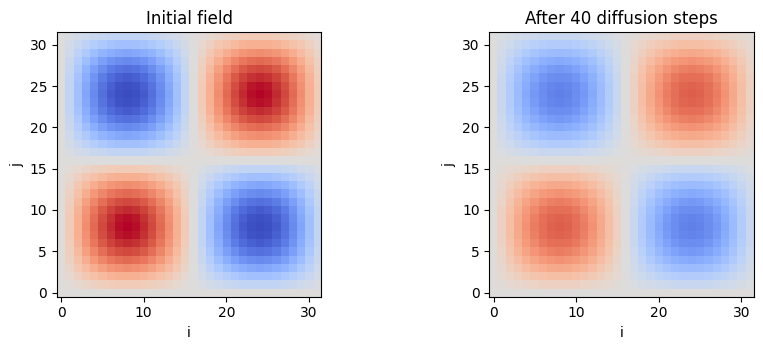

In [12]:
fig,axs=plt.subplots(1,2,figsize=(9,3.6))
axs[0].imshow(np.asarray(u0),origin='lower',cmap='coolwarm',vmin=-1,vmax=1)
axs[0].set_title('Initial field')
axs[1].imshow(np.asarray(u_end),origin='lower',cmap='coolwarm',vmin=-1,vmax=1)
axs[1].set_title('After 40 diffusion steps')
for a in axs:
    a.set_xlabel('i'); a.set_ylabel('j')
plt.tight_layout(); plt.show()

## 10. 可微分模拟器：由观测反推扩散系数

我们“观测”由真实参数 $\nu_\mathrm{true}$ 模拟产生的目标场，试着通过自动微分最小化：

$$\mathcal{L}(\nu)=\frac{1}{N}\sum_{j,i}
\big(u_{j,i}(T;\nu)-u_{j,i}^{\mathrm{target}}\big)^2.$$

JAX 的 `jax.grad(loss)` 可以**穿过离散时间推进过程**计算对 $\nu$ 的导数。

这是可微分数值模型的核心概念之一。不过，完整 CFD 逆问题可能需要隐式求导、伴随方法、检查点和处理长期梯度的技术。

In [13]:
target_field, _=rollout_jit(u0,nu_true,dt,dx,dy,40)

def parameter_loss(nu):
    prediction,_=rollout_jit(u0,nu,dt,dx,dy,40)
    return jnp.mean((prediction-target_field)**2)

loss_and_grad=jax.jit(jax.value_and_grad(parameter_loss))
for trial_nu in [0.02,0.04,0.06,0.08]:
    loss, grad=loss_and_grad(jnp.asarray(trial_nu))
    print(f'nu={trial_nu:.3f} loss={float(loss):.6e} grad={float(grad):+.4e}')

nu=0.020 loss=6.183202e-03 grad=-3.3862e-01
nu=0.040 loss=1.406194e-03 grad=-1.4723e-01
nu=0.060 loss=0.000000e+00 grad=+0.0000e+00
nu=0.080 loss=1.168134e-03 grad=+1.1147e-01


### 10.1 试一试：一维参数的梯度下降

这是教学演示，学习率不保证对所有参数和离散方案适合；仅用稳定范围内的参数搜索，避免显式积分数值爆炸。

In [14]:
nu_guess=jnp.asarray(0.025,dtype=u0.dtype)
trajectory=[]
for it in range(25):
    loss, grad=loss_and_grad(nu_guess)
    trajectory.append((float(nu_guess),float(loss)))
    nu_guess=jnp.clip(nu_guess-0.06*grad,0.005,0.12)
print('initial guess / final:',trajectory[0][0],float(nu_guess))
print('initial / final loss:',trajectory[0][1],float(parameter_loss(nu_guess)))
assert np.isfinite(float(nu_guess))

initial guess / final: 0.02500000037252903 0.05999987572431564
initial / final loss: 0.004622755106538534 5.5731860912257986e-14


## 11. 与你未来的 CFD 求解器的联系

一个更完整的可微分不可压流 CFD 求解器通常还要加入：

1. 速度场 `(u,v)` 的连续性方程与动量方程；
2. 对流离散、黏性项及稳定推进；
3. 压力 Poisson 系统及投影步骤；
4. 圆柱几何、合适入口/出口/壁面边界与无滑移；
5. 力/阻力计算、网格/时间步收敛验证；
6. 基于代理模型的策略训练与离线/在线验证。

因此这节课是数据结构与 JAX 基础的**课程终点**，但不是二维圆柱绕流 CFD 训练的终点。

---
## 12. 编程练习

**练习 1：** 实现 `periodic_laplacian(u,dx,dy)`，输入二维 JAX 数组，使用中心差分和 `jnp.roll`，返回相同形状的 JAX 数组。

In [15]:
def periodic_laplacian(u,dx,dy):
    # TODO: jnp.roll 处理 axis=0/1
    return None

**练习 2：** 实现 `jax_squared_loss(weights, features, targets)`。其中 `features` 为 `(batch,dim)`，`weights` 为 `(dim,)`，`targets` 为 `(batch,)`。计算 `mean((features @ weights - targets)**2)`，应能用 `jax.grad` 求梯度。

In [16]:
def jax_squared_loss(weights,features,targets):
    # TODO: 使用 jnp，不要转成 numpy
    return None

**练习 3：** 实现 `diffusion_step(u,nu,dt,dx,dy)`。用练习 1 的离散 Laplace 实现一步显式 Euler；要求返回新的 JAX 数组，不修改输入。

In [17]:
def diffusion_step(u,nu,dt,dx,dy):
    # TODO: u + dt*nu*periodic_laplacian(...)
    return None

## 练习自测

运行下方测试。`TODO` 未完成时出现“尚未通过”属于正常情况；逐项填入你的实现并再次运行。本讲的测试检查正确性与边界条件，性能优化可在通过后继续尝试。

In [18]:
def check(name, test_fn):
    try:
        test_fn()
        print(f"✅ {name}：通过")
    except Exception as exc:
        print(f"⬜ {name}：尚未通过 — {type(exc).__name__}: {exc}")

In [19]:
def test_ex1():
    a=jnp.ones((7,9))
    result=periodic_laplacian(a,0.2,0.3)
    assert result is not None and result.shape == a.shape
    assert np.allclose(np.asarray(result),0,atol=1e-5)
    v=jnp.arange(35,dtype=jnp.float32).reshape(5,7)
    assert np.allclose(np.asarray(periodic_laplacian(v,0.2,0.3)),
                       np.asarray(periodic_laplacian_demo(v,0.2,0.3)))

def test_ex2():
    X=jnp.array([[1.,0.],[0.,1.],[1.,1.]])
    y=jnp.array([1.,2.,3.])
    w=jnp.array([1.,2.])
    loss=jax_squared_loss(w,X,y)
    assert abs(float(loss)) < 1e-7
    grad=jax.grad(jax_squared_loss)(jnp.array([0.,0.]),X,y)
    assert grad.shape == w.shape
    expected=np.asarray((2/3)*X.T @ (X @ jnp.zeros(2)-y))
    assert np.allclose(np.asarray(grad),expected,rtol=1e-5,atol=1e-6)

def test_ex3():
    a=jnp.array(np.asarray(u0))
    before=np.asarray(a).copy()
    result=diffusion_step(a,0.06,0.001,dx,dy)
    assert result is not None and result.shape == a.shape
    assert np.allclose(np.asarray(result),
                       np.asarray(heat_step_demo(a,0.06,0.001,dx,dy)),rtol=1e-5,atol=1e-5)
    assert np.allclose(np.asarray(a),before), 'do not mutate input'
    assert float(jnp.mean(result**2)) <= float(jnp.mean(a**2))+1e-6

check('练习 1 / 周期 Laplace 算子',test_ex1)
check('练习 2 / 可微损失函数',test_ex2)
check('练习 3 / 扩散时间步',test_ex3)

⬜ 练习 1 / 周期 Laplace 算子：尚未通过 — AssertionError: 
⬜ 练习 2 / 可微损失函数：尚未通过 — TypeError: float() argument must be a string or a real number, not 'NoneType'
⬜ 练习 3 / 扩散时间步：尚未通过 — AssertionError: 


## 13. 参考答案

In [20]:
def periodic_laplacian_solution(u,dx,dy):
    return ((jnp.roll(u,-1,axis=1)-2*u+jnp.roll(u,1,axis=1))/dx**2 +
            (jnp.roll(u,-1,axis=0)-2*u+jnp.roll(u,1,axis=0))/dy**2)

def jax_squared_loss_solution(weights,features,targets):
    return jnp.mean((features @ weights-targets)**2)

def diffusion_step_solution(u,nu,dt,dx,dy):
    return u + dt*nu*periodic_laplacian_solution(u,dx,dy)

assert np.allclose(np.asarray(periodic_laplacian_solution(jnp.ones((4,5)),1,1)),0)
assert np.isfinite(np.asarray(jax.grad(jax_squared_loss_solution)(
    jnp.zeros(2),jnp.ones((3,2)),jnp.ones(3)))).all()
assert diffusion_step_solution(u0,0.06,0.001,dx,dy).shape == u0.shape
print('✅ 参考答案自测通过')

✅ 参考答案自测通过


## 14. 整套课程的知识地图

| 知识 | 你现在可以做什么 | 下一步应用 |
|:--|:--|:--|
| Array / index | 表示二维场变量、离散索引 | 速度/压力场与边界条件 |
| Stack / Queue | 管理待处理任务、网格搜索 | 计算域连通性 |
| Dict / Set | 快速索引网格元数据 | 边界标签、网格拓扑 |
| Linked list / Ring | 管理历史状态和有限容量缓存 | CFD 收敛日志、RL replay buffer |
| Tree / Heap | 层级空间剖分、优先任务 | AMR 与计算调度 |
| Graph | 保存非结构化网格连接 | 单元邻接与分区 |
| COO / CSR | 组装稀疏线性方程组 | Poisson、扩散与压力方程 |
| NumPy / JAX | 批量数值运算和自动微分 | 可微分 CFD / 代理模型 |

**课程之后建议的实践路径：** 二维周期扩散 → 固壁扩散 → 2D 不可压 Navier–Stokes（压力投影）→ 圆柱绕流边界 → 网格与时间收敛 → 阻力/升力 → 可微分与控制。

## 15. 自测与挑战

1. `.at[].set()` 为什么要重新接收返回值？
2. `jit` 首次编译耗时为什么不应与稳定运行时间混为一谈？
3. `jax.grad(loss)` 求的是离散程序的梯度，还是连续 PDE 的解析梯度？两者如何验证一致？
4. `lax.scan` 在时间推进中承担什么角色？
5. 为什么使用周期 `roll` 的扩散算子不能直接套到有入口、出口和圆柱固壁的算例？
6. 显式扩散步长受什么稳定条件限制？
7. GPU 能否让所有稀疏线性代数算法自动比 CPU 更快？为什么？

**选做综合挑战**：用 `jax.grad` 对初始条件的某个可微参数求导，并与中心差分的有限差分梯度进行对照；记录不同步数下的梯度误差。